In [1]:
#Packages used in this project
import pandas as pd
import numpy as np

import seaborn as sns
sns.set_style("whitegrid")
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

from lightgbm import LGBMClassifier, LGBMRegressor, early_stopping
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import roc_curve, roc_auc_score, mean_squared_error

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
data = pd.concat([train.drop(columns=['target', 'ID']), test.drop(columns=['ID'])], axis=0)

In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4459 entries, 0 to 4458
Columns: 4993 entries, ID to 9fc776466
dtypes: float64(1845), int64(3147), object(1)
memory usage: 169.9+ MB


In [4]:
train.shape

(4459, 4993)

In [5]:
train.select_dtypes(include='object')

,ID
0,000d6aaf2
1,000fbd867
2,0027d6b71
3,0028cbf45
4,002a68644
...,...
4454,ff85154c8
4455,ffb6b3f4f
4456,ffcf61eb6
4457,ffea67e98


In [6]:
train_missing_values = train.isnull().sum()
train_missing_values = train_missing_values[train_missing_values > 0]
print(train_missing_values)

Series([], dtype: int64)


In [7]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49342 entries, 0 to 49341
Columns: 4992 entries, ID to 9fc776466
dtypes: float64(4991), object(1)
memory usage: 1.8+ GB


In [8]:
test.shape

(49342, 4992)

In [9]:
test.select_dtypes(include='object')

,ID
0,000137c73
1,00021489f
2,0004d7953
3,00056a333
4,00056d8eb
...,...
49337,fff73b677
49338,fff7b5923
49339,fff7c698f
49340,fff8dba89


In [10]:
test_missing_values = test.isnull().sum()
test_missing_values = test_missing_values[test_missing_values > 0]
print(test_missing_values)

Series([], dtype: int64)


In [11]:
train = train.drop("ID", axis=1)
IDs = test.pop("ID")

In [12]:
train_statistics = pd.DataFrame(zip(train.mean(), train.var()), columns=["Mean", "Variance"])

In [13]:
train_statistics

,Mean,Variance
0,5.944923e+06,6.780389e+13
1,1.465493e+04,1.515777e+11
2,1.390895e+03,4.132307e+09
3,2.672245e+04,3.248603e+11
4,4.530164e+03,5.565466e+10
...,...,...
4987,1.213809e+05,2.228509e+13
4988,3.573451e+04,2.607005e+12
4989,3.123741e+05,1.864945e+13
4990,9.219960e+04,2.676474e+12


[Text(0.5, 1.0, 'Means of the features')]

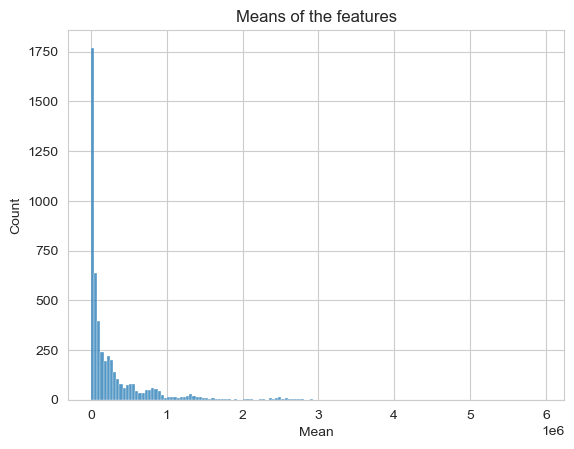

In [14]:
sns.histplot(data=train_statistics["Mean"]).set(title="Means of the features")

[Text(0.5, 1.0, 'Variances of the features')]

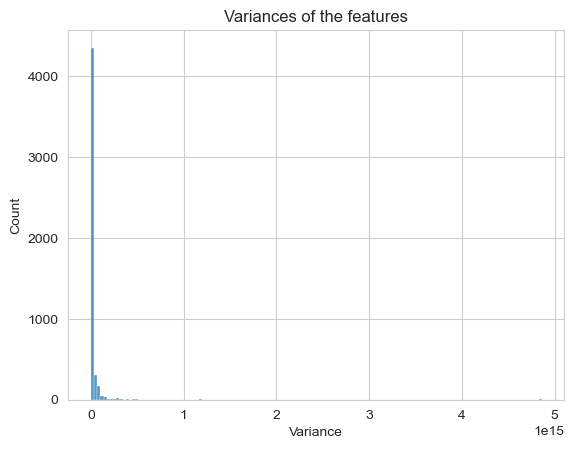

In [15]:
sns.histplot(data=train_statistics["Variance"]).set(title="Variances of the features")

In [16]:
# a rigorous filtering strategy  for the train dataset which is essential
# features that are all zero everywhere
all_zero_features = [c for c in train.columns if (train[c] == 0).all()]
print("Features that are zero:", len(all_zero_features))

# features with constant values
constant_features = [c for c in train.columns if train[c].nunique() == 1]
print("Features with constant values:", len(constant_features))

# duplicates
dupes = train.drop(columns=constant_features).T.duplicated()
duplicate_features = dupes[dupes].index.tolist()
print("Features with duplicate values:", len(duplicate_features))

Features that are zero: 256
Features with constant values: 256
Features with duplicate values: 5


Performed the same operation on the test dataset and no such features were found. Additionally, checked for highly correlated features with correlation higher than a threshold (0.99) which also was not found.

In [17]:
features = [c for c in data.columns if c not in constant_features and c not in duplicate_features]

[Text(0.5, 1.0, 'Target Distribution')]

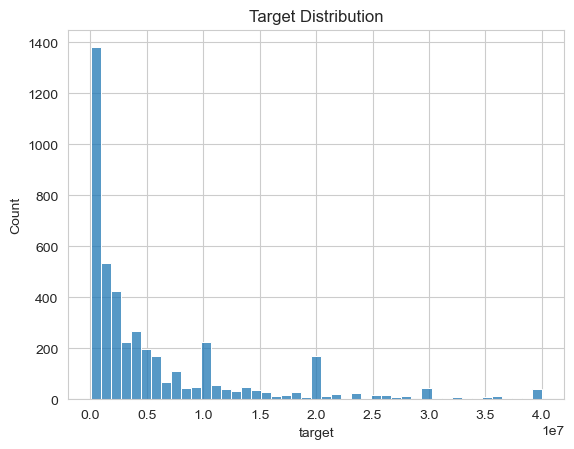

In [18]:
sns.histplot(data=train["target"]).set(title="Target Distribution")

In [19]:
target_corr = train[features].astype('float32').apply(lambda col: col.corr(np.log1p(train["target"])))
target_corr = target_corr.sort_values(key=abs, ascending=False)
print(target_corr.head(30))

9fd594eec    0.197227
f190486d6    0.195313
6eef030c1    0.194630
58e2e02e6    0.187259
70feb1494    0.173549
f74e8f13d    0.172804
26fc93eb7    0.172285
1702b5bf0    0.168431
fb49e4212    0.167091
58232a6fb    0.163608
fc99f9426    0.161864
1c71183bb    0.160103
20aa07010    0.159419
324921c7b    0.159375
ba4ceabc5    0.158138
963a49cdc    0.157060
b43a7cfd5    0.157013
f3cf9341c    0.155248
491b9ee45    0.154638
e1d0e11b5    0.153776
0e1f6696a    0.153263
eeb9cd3aa    0.153056
555f18bd3    0.153014
c8d582dd2    0.152873
9d5c7cb94    0.152748
d6bb78916    0.152660
66ace2992    0.152624
15ace8c9f    0.152088
ac30af84a    0.149510
f14b57b8f    0.149012
dtype: float64


In [20]:
# Adversarial validation
n_train = len(train)
adv_X = data[features]
adv_y = np.concatenate([np.zeros(n_train), np.ones(len(data) - n_train)])
 
adv_model = LGBMClassifier(n_estimators=200, verbose=-1, random_state=42)
adv_auc_cv = cross_val_score(adv_model, adv_X, adv_y, cv=5, scoring='roc_auc')
print(f"Adversarial AUC (5-fold): {adv_auc_cv.mean():.3f} +/- {adv_auc_cv.std():.3f}")
 
adv_model.fit(adv_X, adv_y)
adv_probailities = adv_model.predict_proba(adv_X)[:, 1]
false_positive_rate, true_positive_rate, _ = roc_curve(adv_y, adv_probailities)

Adversarial AUC (5-fold): 0.948 +/- 0.004


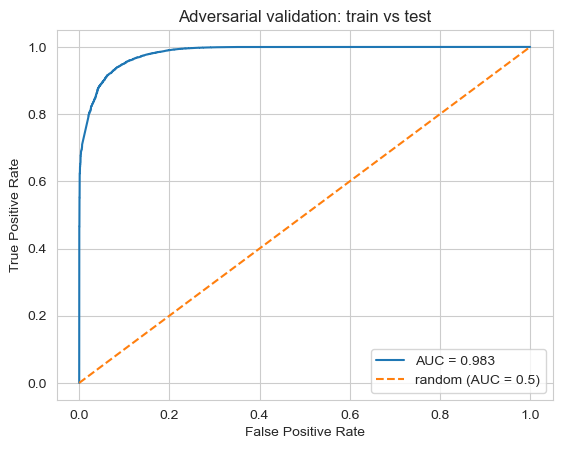

In [21]:
plt.plot(false_positive_rate, true_positive_rate, label=f'AUC = {roc_auc_score(adv_y, adv_probailities):.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='random (AUC = 0.5)')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Adversarial validation: train vs test")
plt.legend()
plt.show()

In [22]:
# if AUC is high, inspect which features are driving the shift:
shift_importance = pd.Series(adv_model.feature_importances_, index=features)
print(shift_importance.sort_values(ascending=False).head(20))

58e2e02e6    28
9fd594eec    23
0ff32eb98    23
f190486d6    21
91f701ba2    19
adb64ff71    19
15ace8c9f    18
20aa07010    17
c5a231d81    17
324921c7b    17
1702b5bf0    16
66ace2992    15
58e056e12    15
b625fe55a    15
6619d81fc    15
70feb1494    14
d6bb78916    14
190db8488    14
9df4daa99    14
26628e8d8    13
dtype: int32


In [23]:
# log transform
y_log = np.log1p(train["target"])
train_log = np.log1p(train[features])
test_log = np.log1p(test[features])

[Text(0.5, 1.0, 'log1p(target)')]

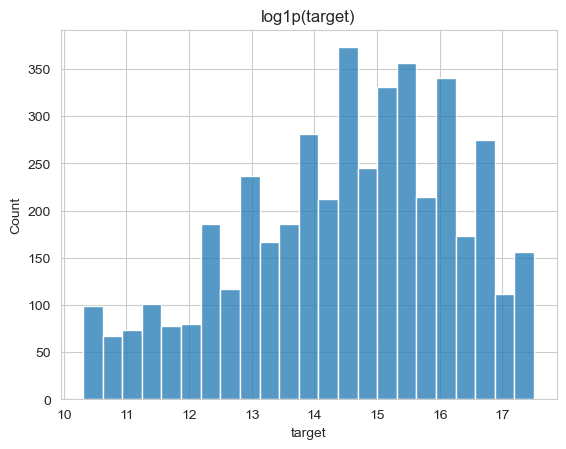

In [24]:
sns.histplot(data=y_log).set(title="log1p(target)")

In [25]:
def rmsle_log_space(y_true_log, y_predicted_log):
    return np.sqrt(mean_squared_error(y_true_log, y_predicted_log))

In [26]:
# Baselines
kf = KFold(n_splits=5, shuffle=True, random_state=42)

LGB_PARAMS = dict(
    n_estimators=1000,
    learning_rate=0.01,
    num_leaves=15,
    min_child_samples=30,
    colsample_bytree=0.7,
    subsample=0.7,
    subsample_freq=1,
    verbose=-1,
    random_state=42 
)

mean_scores, lgb_scores = [], []

for train_idx, val_idx in kf.split(train):
    y_true, y_validation = y_log.iloc[train_idx], y_log.iloc[val_idx]

    # regularized LightGBM baseline — kept conservative since features > rows
    X_true = train[features].iloc[train_idx]
    X_validation = train[features].iloc[val_idx]
    model = LGBMRegressor(**LGB_PARAMS)
    model.fit(
        X_true, y_true,
        eval_set=[(X_validation, y_validation)],
        callbacks=[early_stopping(50, verbose=False)],
    )
    lgb_predicted = model.predict(X_validation, num_iteration=model.best_iteration_)
    lgb_scores.append(rmsle_log_space(y_validation, lgb_predicted))

# naive baseline
mean_scores = []
for train_idx, val_idx in kf.split(train):
    y_true, y_validation = y_log.iloc[train_idx], y_log.iloc[val_idx]
    mean_pred = np.full(len(val_idx), y_true.mean())
    mean_scores.append(rmsle_log_space(y_validation, mean_pred))
print(f"Mean baseline RMSLE: {np.mean(mean_scores):.4f}")
print(f"LightGBM baseline RMSLE: {np.mean(lgb_scores):.4f}")

Mean baseline RMSLE: 1.7506
LightGBM baseline RMSLE: 1.4478


In [27]:
ranked_features = [f for f in target_corr.index.tolist() if f in features]
 
sweep_results = {}
for k in [100, 200, 300, 500, 1000]:
    top_k = ranked_features[:k]
    fold_scores = []
    for train_idx, val_idx in kf.split(train):
        y_true, y_validation = y_log.iloc[train_idx], y_log.iloc[val_idx]
        X_true = train[top_k].iloc[train_idx]
        X_validation = train[top_k].iloc[val_idx]
        model = LGBMRegressor(**LGB_PARAMS)
        model.fit(
            X_true, y_true,
            eval_set=[(X_validation, y_validation)],
            callbacks=[early_stopping(50, verbose=False)],
        )
        prediction = model.predict(X_validation, num_iteration=model.best_iteration_)
        fold_scores.append(rmsle_log_space(y_validation, prediction))
    sweep_results[k] = np.mean(fold_scores)
    print(f"top {k} features -> RMSLE {sweep_results[k]:.4f}")
 
best_k = min(sweep_results, key=sweep_results.get)
print(f"\nbest feature count: {best_k} (RMSLE {sweep_results[best_k]:.4f})")

top 100 features -> RMSLE 1.4452
top 200 features -> RMSLE 1.4457
top 300 features -> RMSLE 1.4329
top 500 features -> RMSLE 1.4342
top 1000 features -> RMSLE 1.4380

best feature count: 300 (RMSLE 1.4329)


In [28]:
best_features = ranked_features[:best_k]
 
final_model = LGBMRegressor(**LGB_PARAMS)
final_model.fit(train[best_features], y_log)
 
test_pred_log = final_model.predict(test[best_features])
test_pred = np.expm1(test_pred_log)

In [29]:
feature_importance = pd.Series(final_model.feature_importances_, index=best_features)
print(feature_importance.sort_values(ascending=False).head(30))

f190486d6    356
58e2e02e6    314
eeb9cd3aa    290
15ace8c9f    268
b43a7cfd5    231
20aa07010    213
f74e8f13d    211
fb0f5dbfe    200
9fd594eec    194
1702b5bf0    193
d6bb78916    187
6eef030c1    182
58232a6fb    177
2288333b4    170
c47340d97    168
1184df5c2    164
024c577b9    164
491b9ee45    161
66ace2992    158
58e056e12    158
5c6487af1    148
62e59a501    140
190db8488    135
bb1113dbb    132
fb49e4212    131
fc99f9426    128
26fc93eb7    116
1db387535    114
324921c7b    113
0572565c2    113
dtype: int32


In [30]:
# correlation vs importance overlap
corr_top30 = set(target_corr.head(30).index)
importance_top30 = set(feature_importance.sort_values(ascending=False).head(30).index)
print(f"corr-only: {len(corr_top30 - importance_top30)}, "
      f"importance-only: {len(importance_top30 - corr_top30)}, "
      f"overlap: {len(corr_top30 & importance_top30)}")

# shift-driver overlap with chosen features
shift_top30 = set(shift_importance.sort_values(ascending=False).head(30).index)
overlap_with_model = shift_top30 & set(best_features)
print(f"{len(overlap_with_model)} of top-30 shift-driving features are in best_features:")
print(overlap_with_model)

corr-only: 12, importance-only: 12, overlap: 18
20 of top-30 shift-driving features are in best_features:
{'6619d81fc', 'eeb9cd3aa', '324921c7b', 'c5a231d81', '58e056e12', 'fb0f5dbfe', '190db8488', '15ace8c9f', '66ace2992', '9fd594eec', '58e2e02e6', 'e176a204a', '91f701ba2', '20aa07010', '0ff32eb98', 'f190486d6', '70feb1494', 'adb64ff71', '1702b5bf0', 'd6bb78916'}


In [31]:
submission = pd.DataFrame({"ID": IDs, "target": test_pred})
submission.to_csv("submission.csv", index=False)

In [32]:
def compute_row_aggregates(df, feature_cols):
    X = df[feature_cols]
    nz = X.replace(0, np.nan)  # treat zero as "absent" for nonzero-only stats

    agg = pd.DataFrame(index=df.index)
    agg['nonzero_count'] = nz.notna().sum(axis=1)
    agg['sum_all']       = X.sum(axis=1)
    agg['mean_nonzero']  = nz.mean(axis=1)
    agg['std_nonzero']   = nz.std(axis=1)
    agg['min_nonzero']   = nz.min(axis=1)
    agg['max_nonzero']   = nz.max(axis=1)
    agg['skew_nonzero']  = nz.skew(axis=1)
    agg['kurt_nonzero']  = nz.kurt(axis=1)

    log_X = np.log1p(X)
    agg['mean_of_log'] = log_X.replace(0, np.nan).mean(axis=1)
    agg['log_of_mean'] = np.log1p(agg['mean_nonzero'].fillna(0))

    return agg.fillna(0)  # rows with zero nonzero features get 0 everywhere

train_agg = compute_row_aggregates(train, features)
test_agg = compute_row_aggregates(test, features)

print(train_agg.describe())

       nonzero_count       sum_all  mean_nonzero   std_nonzero   min_nonzero  \
count    4459.000000  4.459000e+03  4.459000e+03  4.459000e+03  4.459000e+03   
mean      157.004485  1.388533e+09  9.841895e+06  1.343774e+07  1.267326e+06   
std       212.078464  2.405958e+09  1.459619e+07  2.253053e+07  8.508120e+06   
min         1.000000  4.000000e+03  4.000000e+03  0.000000e+00  5.200000e+01   
25%        34.000000  1.255689e+08  2.313470e+06  2.705583e+06  1.000000e+04   
50%       103.000000  5.302843e+08  6.082093e+06  8.464595e+06  5.000000e+04   
75%       197.000000  1.518062e+09  1.205906e+07  1.719770e+07  3.650000e+05   
max      1989.000000  2.273642e+10  4.000000e+08  3.102662e+08  4.000000e+08   

        max_nonzero  skew_nonzero  kurt_nonzero  mean_of_log  log_of_mean  
count  4.459000e+03   4459.000000   4459.000000  4459.000000  4459.000000  
mean   9.071128e+07      2.947780     17.357154    14.414256    15.413864  
std    2.478599e+08      2.553544     28.482391    

In [33]:
feature_sets_to_test = {
    'best_300_alone': best_features,
    'best_300_plus_aggregates': best_features + list(train_agg.columns),
}

for name, feat_list in feature_sets_to_test.items():
    X_full = pd.concat([train[best_features], train_agg], axis=1) if 'aggregates' in name else train[best_features]
    fold_scores = []
    for train_idx, val_idx in kf.split(train):
        y_tr, y_val = y_log.iloc[train_idx], y_log.iloc[val_idx]
        X_tr, X_val = X_full.iloc[train_idx], X_full.iloc[val_idx]
        model = LGBMRegressor(**LGB_PARAMS)
        model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)],
                  callbacks=[early_stopping(50, verbose=False)])
        pred = model.predict(X_val, num_iteration=model.best_iteration_)
        fold_scores.append(rmsle_log_space(y_val, pred))
    print(f"{name}: RMSLE {np.mean(fold_scores):.4f}")

best_300_alone: RMSLE 1.4329
best_300_plus_aggregates: RMSLE 1.3501


In [34]:
final_features = best_features + list(train_agg.columns)  # adjust based on step 3's result

X_train_final = pd.concat([train[best_features], train_agg], axis=1)
X_test_final = pd.concat([test[best_features], test_agg], axis=1)

final_model = LGBMRegressor(**LGB_PARAMS)
final_model.fit(X_train_final, y_log)

test_pred_log = final_model.predict(X_test_final)
test_pred = np.clip(np.expm1(test_pred_log), 0, None)

submission = pd.DataFrame({"ID": IDs, "target": test_pred})
submission.to_csv("submission_v2.csv", index=False)